# Detecting Diabetic Retinopathy from Retinal Images Using EfficientNetB3

**Team members:** G.MUKUNDA PRIYA,PATHAN SADIYA, K ABIRAMASREE,K USHASRI UNNATHI
**Course / Guide:** MACHINE LEARNING / Dr.AJAY DILIP KUMAR

## Introduction
Diabetic retinopathy (DR) is an eye problem that can happen to people who have diabetes. When blood sugar stays high for a long time, it slowly damages the small blood vessels at the back of the eye. In the early stages a person usually feels nothing, so the disease often goes unnoticed until their vision is already affected. If it is found early, treatment can stop it from getting worse, which is why regular eye screening is so important.

Screening is usually done by taking a photo of the retina and having a specialist look at it. The problem is that there are not enough specialists in many places, and checking a large number of images by hand takes a lot of time. A computer program that can give a first opinion on these photos could help doctors focus on the patients who need attention the most.

In this project we try to build such a program using deep learning. We use a model called EfficientNetB3 [5] to look at a retinal image and give it a severity grade from 0 to 4 (0 = No DR, 1 = Mild, 2 = Moderate, 3 = Severe, 4 = Proliferative DR).

## Dataset
We used the APTOS 2019 Blindness Detection dataset from Kaggle [1]. It has 3,662 retinal images that were already graded by doctors. About half of the images are healthy (grade 0), so the classes are not balanced. Because of this, we do not rely on accuracy alone. We also check balanced accuracy, quadratic weighted kappa and the confusion matrix.

## What we did
1. Cleaned and prepared the images by cropping the retina and improving the contrast so that small damage is easier to see.
2. Split the data into training (70%), validation (10%) and test (20%) sets.
3. Trained EfficientNetB3 to predict a single severity score instead of five separate classes, since the grades follow an order [2].
4. Improved the predictions by averaging over flipped copies of each image, training two models and tuning the grade cut-offs on the validation set.
5. Tested the final model on images it had never seen and compared it with simpler machine learning methods.
6. Added a cell where new retinal images can be uploaded to get a predicted grade.

## Our contributions beyond the basic pipeline
Most APTOS projects stop at reporting accuracy. After training, we noticed that our model was weak on severe cases, and that a doctor would also want to know *why* and *how sure* the model is. So we added three extensions:
1. **Screening-oriented thresholds (section 13d):** we re-tune the grade cut-offs to value every grade equally, instead of maximising overall accuracy, and show the trade-off for severe cases.
2. **Uncertainty and referral (section 13e):** we measure how much the predictions disagree across flipped views and models, and test whether sending the most uncertain images to a doctor makes the remaining predictions more accurate.
3. **Explainability heatmaps (section 13f):** we show which parts of the retina the model uses for its decision, using class activation maps [13].

These ideas are known in the literature, but we apply and evaluate them together on this problem and report the results honestly, including where they do not help.

## Note
This notebook was made for learning. It is not a medical tool and cannot replace a real eye doctor.

## Research background and design choices

**Dataset:** APTOS 2019 Blindness Detection (3,662 labeled images). **Split:** the same stratified 70/10/20, seed 42 as your earlier runs.

## What other sources say works (and what this notebook implements)
| Finding from published/competition sources | Where it is used here |
|---|---|
| Top APTOS 2019 solutions framed grading as **regression**, not 5-way classification; a top-3% write-up says classification models "weren't well enough" | Single regression output, Huber loss, tuned thresholds |
| Top solutions **pretrained on the 2015 EyePACS data**, then fine-tuned on APTOS 2019 (for example the 43rd-place and 76th-place write-ups, and a paper ranked 54/2943) | Optional EyePACS pretraining stage (section 8) |
| **EfficientNet B3/B4/B5**, crop + circle crop + Ben Graham preprocessing, flip TTA | EfficientNetB3, crop + Ben preprocessing, 4-flip TTA |
| **Ensembles** of several EfficientNets beat every single model (one 40th-place write-up: single val kappa 0.919-0.926, ensemble 0.932) | `SEEDS` ensemble |
| A top-3% write-up found **larger images gave worse results** than 224-256 px with 2015 pretraining | Default `IMG_SIZE = 300` (B3's native size), not 384+ |
| Thresholds for the regression output were tuned (coefficient optimization) | Threshold tuning on validation data |

Sources: github.com/mikelkl/APTOS2019, diyago.github.io/2019/10/04/kaggle-blindness.html, github.com/tahsin314/40th_place_solution_aptos2019-blindness-detection, arxiv.org/abs/2003.02261, arxiv.org/abs/2507.17121, and the ORDER-DR paper on PubMed Central (PMC13477890).

## Realistic accuracy, based on those sources
- A plain EfficientNetB0 at 224 px with softmax scored about **72%** five-class accuracy in one public model card, close to your 68%.
- Recent papers report **about 80-85%** five-class accuracy on APTOS held-out splits. The most carefully validated one I found reports **83.5% ± 1.2%** over several splits. Some papers claim 88-93%, but I could not verify how their splits were built, so treat those numbers with caution.
- Binary (No DR vs DR) accuracy is much higher, in the mid-to-high 90s.
- **Without EyePACS pretraining, expect roughly 76-83%. With it and an ensemble, 80-85% is plausible.** Nobody can promise a number, and a 733-image test set has about ±3% sampling noise.
- This is an educational prototype and not a medical diagnostic system.

**Use a GPU runtime:** Runtime -> Change runtime type -> T4 GPU.

## 1. Install and import libraries

In [1]:
%pip -q install kaggle opencv-python-headless scikit-learn scikit-image seaborn joblib

In [2]:
import os, glob, zipfile, random, warnings, json, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2, tensorflow as tf
from google.colab import files
from skimage.feature import hog
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, cohen_kappa_score)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import sklearn, skimage
warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = 300          # EfficientNetB3 native size; top solutions used 224-300 px
BATCH_SIZE = 16
NUM_CLASSES = 5
SEEDS = [42]            # FIRST RUN: one model. Later change to [42, 7] and re-run the training cell: seed 42 is reloaded, only seed 7 trains.
HEAD_EPOCHS = 6
FINE_EPOCHS = 30
OPTIMIZE_THRESHOLDS_FOR = "accuracy"   # or "qwk"

# Optional but most effective step: pretrain on the 2015 EyePACS data (Kaggle "diabetic-retinopathy-detection").
# Use a RESIZED copy (for example a resized EyePACS dataset on Kaggle) with a CSV that has columns: image, level.
USE_EYEPACS_PRETRAIN = False
EYEPACS_CSV = "/content/eyepacs/trainLabels.csv"
EYEPACS_IMG_DIR = "/content/eyepacs/train"
EYEPACS_MAX_PER_GRADE = 4000      # caps images per grade to keep pretraining about 30-50 minutes on a T4
EYEPACS_HEAD_EPOCHS = 2
EYEPACS_FINE_EPOCHS = 6

# Keep models/checkpoints safe from Colab disconnects: set True to store them in your Google Drive.
USE_DRIVE = False
MODEL_DIR = "/content"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = "/content/drive/MyDrive/aptos_dr"
    os.makedirs(MODEL_DIR, exist_ok=True)
print("Models and checkpoints go to:", MODEL_DIR)

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

Models and checkpoints go to: /content
TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. APTOS 2019 dataset source and download

In [3]:
DATA_DIR=Path("/content/aptos_data"); DATA_DIR.mkdir(parents=True,exist_ok=True)
def locate():
    a=list(DATA_DIR.rglob("train.csv")); b=list(DATA_DIR.rglob("train_images"))
    return (a[0],b[0]) if a and b else (None,None)
CSV_PATH,IMAGE_DIR=locate()
if CSV_PATH is None:
    token_path=Path.home()/".kaggle"/"kaggle.json"; token_path.parent.mkdir(parents=True,exist_ok=True)
    if not token_path.exists():
        print("Select exactly one Kaggle API token JSON file (any filename is okay).")
        uploaded=files.upload(); names=[n for n in uploaded if n.lower().endswith(".json")]
        if len(names)!=1: raise ValueError(f"Choose one .json token file; selected: {list(uploaded)}")
        token=json.loads(uploaded[names[0]].decode("utf-8"))
        if not token.get("username") or not token.get("key"): raise ValueError("Not a valid Kaggle API token JSON; download a fresh token from Kaggle settings.")
        token_path.write_text(json.dumps(token),encoding="utf-8"); os.chmod(token_path,0o600); del token,uploaded
    cli=shutil.which("kaggle")
    if not cli: raise RuntimeError("Kaggle command missing. Rerun the install cell and this cell.")
    result=subprocess.run([cli,"competitions","download","-c","aptos2019-blindness-detection","-p",str(DATA_DIR)],text=True,capture_output=True)
    if result.returncode: print(result.stdout); print(result.stderr); raise RuntimeError("Download failed. Confirm Kaggle token and accepted competition rules.")
    print(result.stdout)
    zips=list(DATA_DIR.glob("*.zip"))
    if zips:
        with zipfile.ZipFile(zips[0]) as z: z.extractall(DATA_DIR)
    CSV_PATH,IMAGE_DIR=locate()
    if CSV_PATH is None: raise FileNotFoundError("Expected train.csv and train_images; check archive/files.")
    try: token_path.unlink(); token_path.parent.rmdir()
    except OSError: pass
else: print("Reusing dataset already in Colab files:",CSV_PATH)
data=pd.read_csv(CSV_PATH)
print("Rows:",len(data),"Images:",IMAGE_DIR); display(data.head())

Select exactly one Kaggle API token JSON file (any filename is okay).


Saving kaggle (4).json to kaggle (4).json


Rows: 3662 Images: /content/aptos_data/train_images


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


## 3. Explore the labels

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


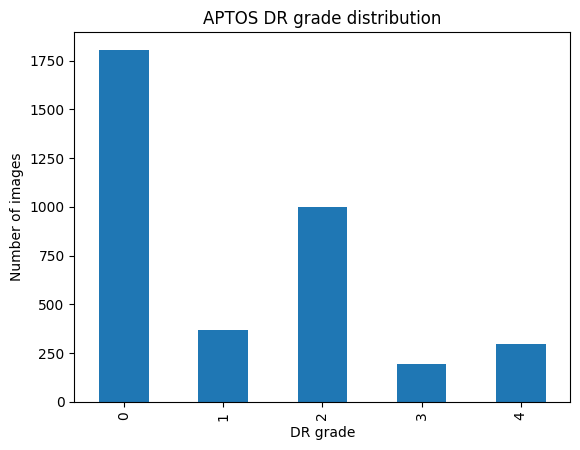

In [4]:
grade_names = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative DR"}
print(data["diagnosis"].value_counts().sort_index())
data["diagnosis"].value_counts().sort_index().plot(kind="bar", title="APTOS DR grade distribution")
plt.xlabel("DR grade"); plt.ylabel("Number of images"); plt.show()

## 4. Stratified 70% / 10% / 20% split
Same split and seed as the original notebook. The test portion is about 733 images and is used only for the final evaluation.

In [5]:
data["image_path"] = data["id_code"].astype(str).apply(lambda x: str(IMAGE_DIR / (x + ".png")))
data = data[data["image_path"].apply(os.path.exists)].reset_index(drop=True)
train_df, temp_df = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data["diagnosis"])
val_df, test_df = train_test_split(temp_df, test_size=(2/3), random_state=SEED, stratify=temp_df["diagnosis"])
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

Train: 2563 | Validation: 366 | Test: 733


## 5. Fundus preprocessing (the largest single improvement)
Each image is cropped to the retina, padded to a square, resized to `IMG_SIZE` × `IMG_SIZE` (300 × 300 by default), and passed through **Ben Graham local-contrast normalization** (subtract a Gaussian-blurred copy). Outside a circular mask the image is set to neutral grey. Preprocessed images are saved to disk once and reused.

Preprocessed images: 3662


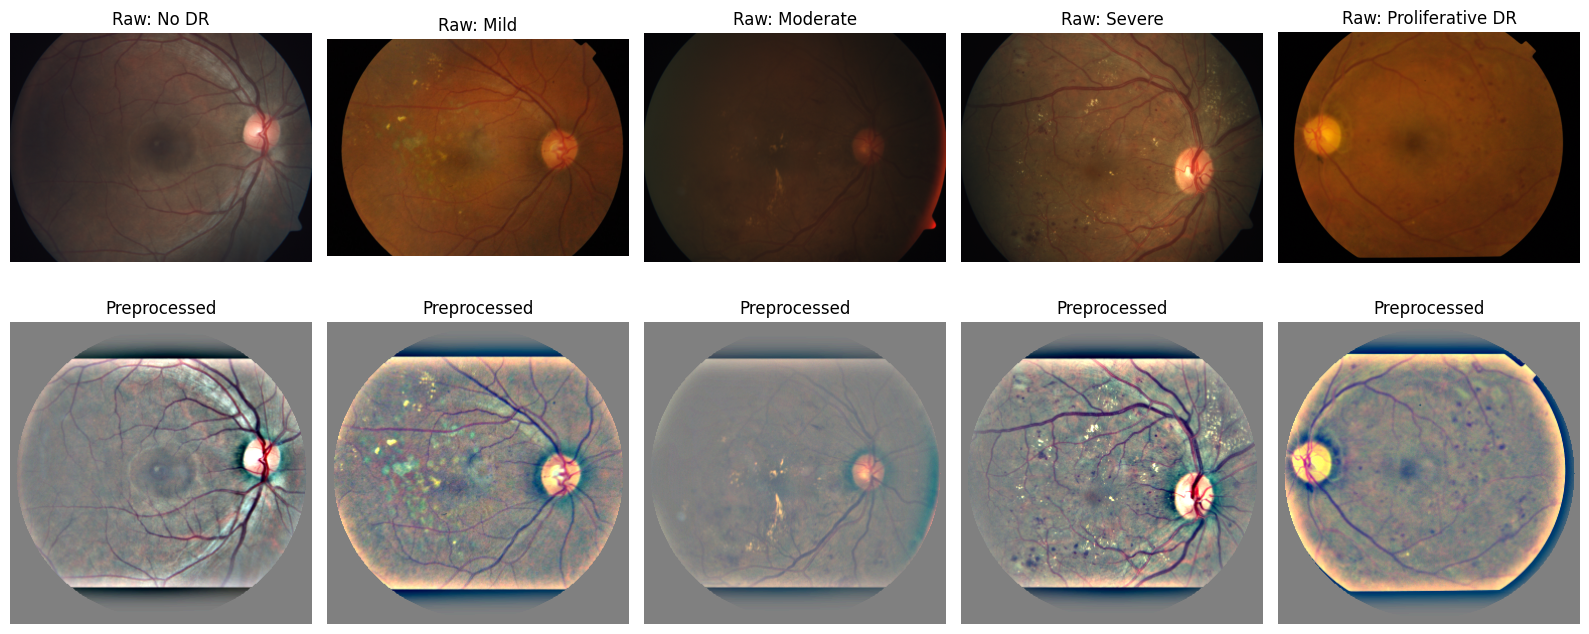

In [6]:
def preprocess_fundus(img_rgb, size=IMG_SIZE):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > 7
    if mask.any():
        ys, xs = np.where(mask)
        img_rgb = img_rgb[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = img_rgb.shape[:2]; s = max(h, w)
    canvas = np.zeros((s, s, 3), dtype=np.uint8)
    canvas[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = img_rgb
    img = cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)
    img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), size/30), -4, 128)
    circle = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(circle, (size//2, size//2), int(size*0.48), 1, -1)
    img = img * circle[:, :, None] + 128 * (1 - circle[:, :, None])
    return img.astype(np.uint8)

PRE_DIR = Path(f"/content/aptos_pre_{IMG_SIZE}"); PRE_DIR.mkdir(exist_ok=True)
def process_one(src, dst):
    if os.path.exists(dst): return
    bgr = cv2.imread(src)
    if bgr is None: raise FileNotFoundError(src)
    out = preprocess_fundus(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    cv2.imwrite(dst, cv2.cvtColor(out, cv2.COLOR_RGB2BGR))

data["pre_path"] = data["id_code"].astype(str).apply(lambda x: str(PRE_DIR / (x + ".png")))
Parallel(n_jobs=-1)(delayed(process_one)(s, d) for s, d in zip(data["image_path"], data["pre_path"]))
for df in (train_df, val_df, test_df):
    df["pre_path"] = df["id_code"].astype(str).apply(lambda x: str(PRE_DIR / (x + ".png")))
print("Preprocessed images:", len(list(PRE_DIR.glob("*.png"))))

fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for g in range(5):
    row = train_df[train_df.diagnosis == g].iloc[0]
    ax[0, g].imshow(cv2.cvtColor(cv2.imread(row.image_path), cv2.COLOR_BGR2RGB)); ax[0, g].set_title(f"Raw: {grade_names[g]}"); ax[0, g].axis("off")
    ax[1, g].imshow(cv2.cvtColor(cv2.imread(row.pre_path), cv2.COLOR_BGR2RGB)); ax[1, g].set_title("Preprocessed"); ax[1, g].axis("off")
plt.tight_layout(); plt.show()

## 6. Input pipeline
Preprocessed images are loaded as float32 in the **0–255** range, which is what EfficientNet expects.

In [7]:
def load_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return image, tf.cast(label, tf.float32)      # kept as uint8 so the cache stays small

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["pre_path"].values, frame["diagnosis"].astype("float32").values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()   # decode PNGs once, not every epoch
    if training: ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)
train_eval_ds = make_dataset(train_df)   # unshuffled, used later for feature extraction

## 7. EfficientNetB3 regression model
The model predicts one continuous severity score (0–4) with a Huber loss. This respects the ordering of the grades, since predicting 3 for a true 4 is better than predicting 0. Thresholds are tuned on the validation set in section 11.

In [8]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB3

def build_model():
    backbone = EfficientNetB3(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    backbone.trainable = False
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="fundus_0_255")
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.5, fill_mode="constant", fill_value=128.0)(x)     # up to +-180 degrees
    x = layers.RandomZoom(0.10, fill_mode="constant", fill_value=128.0)(x)
    x = layers.RandomContrast(0.20)(x)
    x = layers.RandomBrightness(0.15, value_range=(0, 255))(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(1, dtype="float32", name="severity")(x)
    return models.Model(inputs, outputs, name="APTOS_EfficientNetB3_Regressor"), backbone

_m, _ = build_model(); _m.summary(); del _m

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "APTOS_EfficientNetB3_Regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fundus_0_255 (InputLayer)       │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 300, 300, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 300, 300, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 300, 300, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity (Dense)                │ (None, 1)              │         1,537 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,785,072 (41.14 MB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 10,783,535 (41.14 MB)

## 8. Optional EyePACS 2015 pretraining
Set `USE_EYEPACS_PRETRAIN = True` in the settings cell and provide a resized EyePACS copy to use this stage. It trains the same regressor on EyePACS images (grades are on the same 0-4 scale), saves the weights, and every APTOS model then starts from them. If it is `False`, this cell is skipped and the models start from ImageNet weights.

In [9]:
def callbacks_for_training(patience):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)]

PRETRAINED_WEIGHTS = None
if USE_EYEPACS_PRETRAIN:
    ey = pd.read_csv(EYEPACS_CSV).rename(columns={"image": "id_code", "level": "diagnosis"})
    ey = pd.concat([g.sample(min(len(g), EYEPACS_MAX_PER_GRADE), random_state=SEED) for _, g in ey.groupby("diagnosis")])
    exts = {p.stem: str(p) for p in Path(EYEPACS_IMG_DIR).rglob("*") if p.suffix.lower() in (".jpeg", ".jpg", ".png")}
    ey["image_path"] = ey["id_code"].astype(str).map(exts); ey = ey.dropna(subset=["image_path"]).reset_index(drop=True)
    EY_PRE = Path(f"/content/eyepacs_pre_{IMG_SIZE}"); EY_PRE.mkdir(exist_ok=True)
    ey["pre_path"] = ey["id_code"].astype(str).apply(lambda x: str(EY_PRE / (x + ".png")))
    Parallel(n_jobs=-1)(delayed(process_one)(s_, d_) for s_, d_ in zip(ey["image_path"], ey["pre_path"]))
    ey_tr, ey_va = train_test_split(ey, test_size=0.05, random_state=SEED, stratify=ey["diagnosis"])
    print("EyePACS pretraining images:", len(ey_tr), "train /", len(ey_va), "val")
    ey_train_ds, ey_val_ds = make_dataset(ey_tr, training=True), make_dataset(ey_va)
    pm, pb = build_model()
    pm.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.Huber(), metrics=["mae"])
    pm.fit(ey_train_ds, validation_data=ey_val_ds, epochs=EYEPACS_HEAD_EPOCHS, callbacks=callbacks_for_training(3))
    pb.trainable = True
    for l in pb.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    pm.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=tf.keras.losses.Huber(), metrics=["mae"])
    pm.fit(ey_train_ds, validation_data=ey_val_ds, epochs=EYEPACS_FINE_EPOCHS, callbacks=callbacks_for_training(3))
    PRETRAINED_WEIGHTS = "/content/eyepacs_pretrained.weights.h5"; pm.save_weights(PRETRAINED_WEIGHTS)
    del pm, pb, ey_train_ds, ey_val_ds
    print("Saved EyePACS-pretrained weights.")
else:
    print("EyePACS pretraining skipped (USE_EYEPACS_PRETRAIN = False).")

EyePACS pretraining skipped (USE_EYEPACS_PRETRAIN = False).


## 9. Train on APTOS: head first, then fine-tune the whole backbone
Phase 1 trains only the new head (2 epochs if EyePACS-pretrained weights are loaded, otherwise 6). Phase 2 unfreezes the whole backbone, keeping BatchNorm layers frozen, at a lower learning rate, for up to 30 epochs. Early stopping restores the best validation weights. One model is trained per seed in `SEEDS`.

In [10]:
def train_one(seed):
    ck = lambda tag: tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/ckpt_seed{seed}_{tag}.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True)
    tf.keras.utils.set_random_seed(seed)
    model, backbone = build_model()
    if PRETRAINED_WEIGHTS: model.load_weights(PRETRAINED_WEIGHTS)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.Huber(), metrics=["mae"])
    h1 = model.fit(train_ds, validation_data=val_ds, verbose=2, epochs=(2 if PRETRAINED_WEIGHTS else HEAD_EPOCHS), callbacks=callbacks_for_training(3) + [ck("head")])
    backbone.trainable = True
    for l in backbone.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=tf.keras.losses.Huber(), metrics=["mae"])
    h2 = model.fit(train_ds, validation_data=val_ds, verbose=2, epochs=FINE_EPOCHS, callbacks=callbacks_for_training(8) + [ck("fine")])
    return model, {k: h1.history[k] + h2.history[k] for k in h1.history}

trained, histories = [], []
for s in SEEDS:
    path = f"{MODEL_DIR}/aptos_effnetb3_seed{s}.keras"
    if os.path.exists(path):                      # resume: reuse a seed that already finished
        print(f"\n===== Seed {s}: found {path}, loading instead of retraining =====")
        trained.append(tf.keras.models.load_model(path, compile=False)); histories.append(None)
        continue
    print(f"\n===== Training model with seed {s} =====")
    m, h = train_one(s); trained.append(m); histories.append(h)
    m.save(path)



===== Training model with seed 42 =====
Epoch 1/6
161/161 - 61s - 378ms/step - loss: 0.3590 - mae: 0.6931 - val_loss: 0.2647 - val_mae: 0.5563 - learning_rate: 0.0010
Epoch 2/6
161/161 - 21s - 128ms/step - loss: 0.2734 - mae: 0.5812 - val_loss: 0.2577 - val_mae: 0.5386 - learning_rate: 0.0010
Epoch 3/6
161/161 - 20s - 125ms/step - loss: 0.2521 - mae: 0.5501 - val_loss: 0.2771 - val_mae: 0.5731 - learning_rate: 0.0010
Epoch 4/6
161/161 - 20s - 127ms/step - loss: 0.2439 - mae: 0.5425 - val_loss: 0.3010 - val_mae: 0.6066 - learning_rate: 0.0010
Epoch 5/6
161/161 - 21s - 132ms/step - loss: 0.2431 - mae: 0.5455 - val_loss: 0.2706 - val_mae: 0.5527 - learning_rate: 0.0010
Epoch 1/30
161/161 - 149s - 925ms/step - loss: 0.2490 - mae: 0.5385 - val_loss: 0.1838 - val_mae: 0.4289 - learning_rate: 1.0000e-04
Epoch 2/30
161/161 - 51s - 319ms/step - loss: 0.1675 - mae: 0.4100 - val_loss: 0.1965 - val_mae: 0.4029 - learning_rate: 1.0000e-04
Epoch 3/30
161/161 - 50s - 312ms/step - loss: 0.1364 - mae:

## 10. Plot training curves

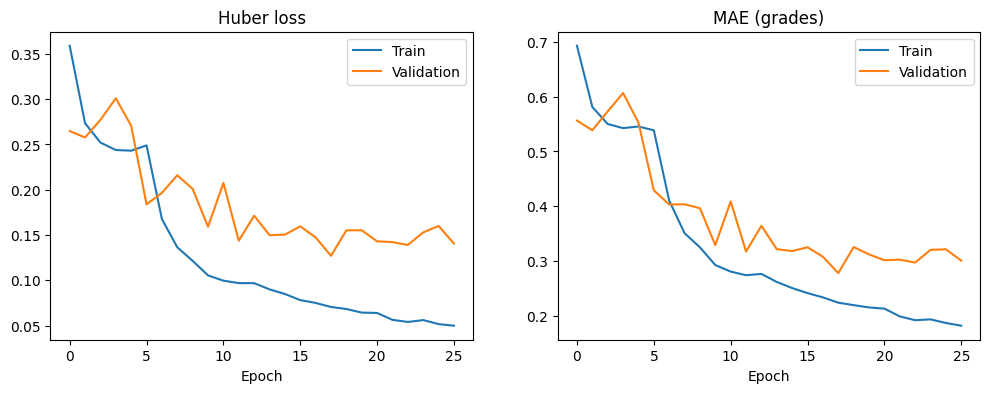

In [13]:
h = next((x for x in histories if x is not None), None)
if h is None: raise SystemExit("Training curves unavailable: all models were loaded from disk.")
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(h["loss"], label="Train"); plt.plot(h["val_loss"], label="Validation"); plt.title("Huber loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1,2,2); plt.plot(h["mae"], label="Train"); plt.plot(h["val_mae"], label="Validation"); plt.title("MAE (grades)"); plt.xlabel("Epoch"); plt.legend()
plt.show()

## 11. Predictions with test-time augmentation, then threshold tuning on validation
Predictions are averaged over the original image and its horizontal, vertical and both flips (and over all trained models if you used several seeds). Grade thresholds are then tuned **on the validation set only**; the test set stays untouched.

In [14]:
def predict_tta(model, ds):
    fns = [lambda x: x, tf.image.flip_left_right, tf.image.flip_up_down,
           lambda x: tf.image.flip_left_right(tf.image.flip_up_down(x))]
    outs = []
    for fn in fns:
        outs.append(model.predict(ds.map(lambda x, y: (fn(x), y)), verbose=0).ravel())
    return np.mean(outs, axis=0)

def predict_ensemble(ds):
    return np.clip(np.mean([predict_tta(m, ds) for m in trained], axis=0), 0, 4)

yv = val_df["diagnosis"].astype(int).values
yt = test_df["diagnosis"].astype(int).values
ytr = train_df["diagnosis"].astype(int).values
val_scores  = predict_ensemble(val_ds)
test_scores = predict_ensemble(test_ds)

def to_grade(scores, thr): return np.digitize(scores, np.sort(thr))
def objective(y, p):
    if OPTIMIZE_THRESHOLDS_FOR == "qwk": return cohen_kappa_score(y, p, weights="quadratic")
    return accuracy_score(y, p) + 0.01 * cohen_kappa_score(y, p, weights="quadratic")

def tune_thresholds(scores, y):
    thr = [0.5, 1.5, 2.5, 3.5]; best = objective(y, to_grade(scores, thr))
    for _ in range(4):
        for i in range(4):
            for cand in np.linspace(thr[i]-0.6, thr[i]+0.6, 61):
                t = thr.copy(); t[i] = cand
                sc = objective(y, to_grade(scores, t))
                if sc > best: best, thr = sc, t
    return sorted(thr)

default_thr = [0.5, 1.5, 2.5, 3.5]
tuned_thr = tune_thresholds(val_scores, yv)
print("Default thresholds:", default_thr)
print("Tuned thresholds  :", [round(t, 3) for t in tuned_thr])
print("Validation accuracy (default):", round(accuracy_score(yv, to_grade(val_scores, default_thr)), 4))
print("Validation accuracy (tuned)  :", round(accuracy_score(yv, to_grade(val_scores, tuned_thr)), 4))
json.dump({"thresholds": tuned_thr, "img_size": IMG_SIZE}, open(f"{MODEL_DIR}/aptos_thresholds.json", "w"))

Default thresholds: [0.5, 1.5, 2.5, 3.5]
Tuned thresholds  : [np.float64(0.26), np.float64(1.36), np.float64(2.88), np.float64(3.36)]
Validation accuracy (default): 0.8115
Validation accuracy (tuned)  : 0.8415


## 12. Held-out test evaluation

Algorithm            EfficientNetB3 regression
Accuracy                               0.81719
Balanced accuracy                     0.591109
Macro precision                       0.661631
Macro recall                          0.591109
Macro F1                              0.609122
Weighted F1                           0.802972
Quadratic kappa                       0.904476

Per-grade metrics:
                  precision    recall  f1-score   support

           No DR       0.98      0.98      0.98       361
            Mild       0.60      0.47      0.53        74
        Moderate       0.68      0.89      0.77       200
          Severe       0.33      0.13      0.19        39
Proliferative DR       0.71      0.49      0.58        59

        accuracy                           0.82       733
       macro avg       0.66      0.59      0.61       733
    weighted avg       0.81      0.82      0.80       733



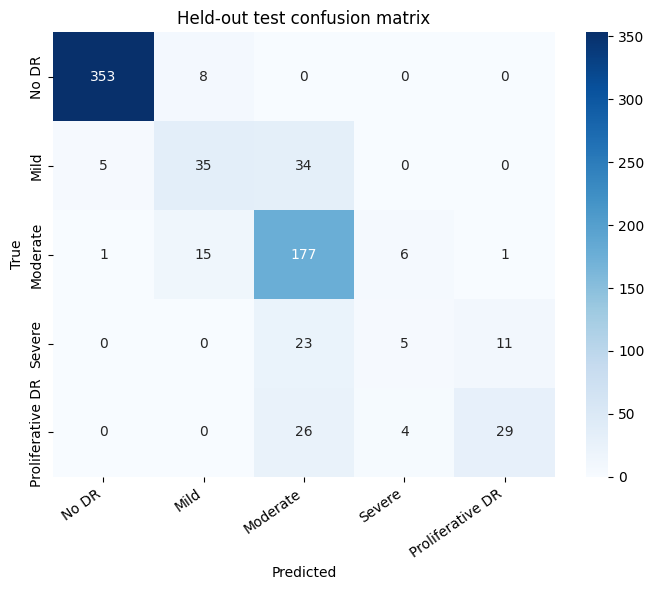

Binary No DR vs DR signs: {'Accuracy': 0.9809, 'Precision': 0.9786, 'Sensitivity': 0.9839, 'Specificity': np.float64(0.9778), 'F1': 0.9812}
Adjacent-grade accuracy (within +-1 grade): 0.9618


In [15]:
def metric_row(name, truth, pred):
    return {"Algorithm": name, "Accuracy": accuracy_score(truth, pred), "Balanced accuracy": balanced_accuracy_score(truth, pred),
            "Macro precision": precision_score(truth, pred, average="macro", zero_division=0),
            "Macro recall": recall_score(truth, pred, average="macro", zero_division=0),
            "Macro F1": f1_score(truth, pred, average="macro", zero_division=0),
            "Weighted F1": f1_score(truth, pred, average="weighted", zero_division=0),
            "Quadratic kappa": cohen_kappa_score(truth, pred, weights="quadratic")}

y_pred = to_grade(test_scores, tuned_thr)
print(pd.Series(metric_row("EfficientNetB3 regression", yt, y_pred)).to_string())
print("\nPer-grade metrics:")
print(classification_report(yt, y_pred, labels=[0,1,2,3,4], target_names=[grade_names[i] for i in range(5)], zero_division=0))
cm = confusion_matrix(yt, y_pred, labels=[0,1,2,3,4])
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[grade_names[i] for i in range(5)], yticklabels=[grade_names[i] for i in range(5)])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Held-out test confusion matrix"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

yb = (yt > 0).astype(int); pb = (y_pred > 0).astype(int)
tn, fp, fn, tp = confusion_matrix(yb, pb, labels=[0,1]).ravel()
print("Binary No DR vs DR signs:", {"Accuracy": round(accuracy_score(yb, pb), 4), "Precision": round(precision_score(yb, pb, zero_division=0), 4),
      "Sensitivity": round(recall_score(yb, pb, zero_division=0), 4), "Specificity": round(tn/(tn+fp), 4), "F1": round(f1_score(yb, pb, zero_division=0), 4)})
print("Adjacent-grade accuracy (within +-1 grade):", round(np.mean(np.abs(yt - y_pred) <= 1), 4))

## 13. Compare with classical models
Two comparisons use the same classifiers (Random Forest, SVM, KNN): one on **HOG features** as in the original notebook, and one on **CNN embeddings** from the trained network. HOG is expected to stay near the majority-class baseline, while embeddings should be much stronger.

Train HOG: 500/2563
Train HOG: 1000/2563
Train HOG: 1500/2563
Train HOG: 2000/2563
Train HOG: 2500/2563
Train HOG: 2563/2563
Val HOG: 366/366
Test HOG: 500/733
Test HOG: 733/733
HOG shapes: (2563, 8100) | Embedding shapes: (2563, 1536)


,Algorithm,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Quadratic kappa
5,SVM (CNN embeddings),0.835,0.691,0.707,0.691,0.698,0.834,0.910
4,Random Forest (CNN embeddings),0.825,0.619,0.700,0.619,0.638,0.814,0.897
6,KNN (CNN embeddings),0.824,0.631,0.683,0.631,0.650,0.817,0.900
0,EfficientNetB3 regression (TTA + tuned thresholds),0.817,0.591,0.662,0.591,0.609,0.803,0.904
2,SVM (HOG),0.759,0.480,0.610,0.480,0.486,0.725,0.755
1,Random Forest (HOG),0.744,0.441,0.583,0.441,0.437,0.696,0.704
3,KNN (HOG),0.729,0.496,0.542,0.496,0.497,0.717,0.676


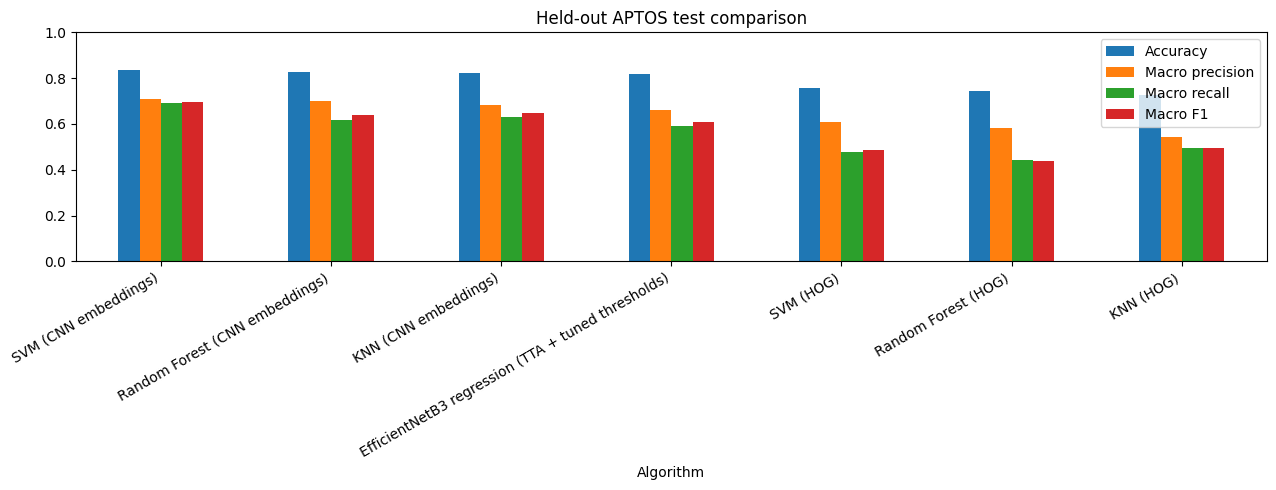

In [16]:
HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm="L2-Hys", feature_vector=True)
def extract_hog_features(frame, name):
    rows = []
    for i, path in enumerate(frame["image_path"].tolist()):
        gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
        rows.append(hog(cv2.resize(gray, (128,128), interpolation=cv2.INTER_AREA), **HOG_SETTINGS))
        if (i+1) % 500 == 0 or i+1 == len(frame): print(f"{name}: {i+1}/{len(frame)}")
    return np.asarray(rows, dtype=np.float32)
hog_train = extract_hog_features(train_df, "Train HOG"); hog_val = extract_hog_features(val_df, "Val HOG"); hog_test = extract_hog_features(test_df, "Test HOG")

feat_model = models.Model(trained[0].input, trained[0].get_layer("gap").output)
emb_train = feat_model.predict(train_eval_ds, verbose=0).astype(np.float32)
emb_val   = feat_model.predict(val_ds, verbose=0).astype(np.float32)
emb_test  = feat_model.predict(test_ds, verbose=0).astype(np.float32)
print("HOG shapes:", hog_train.shape, "| Embedding shapes:", emb_train.shape)

def make_models():
    return {"Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, class_weight="balanced"),
            "SVM": make_pipeline(StandardScaler(), SVC(C=3, kernel="rbf", class_weight="balanced")),
            "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance"))}

test_predictions = {"EfficientNetB3 regression (TTA + tuned thresholds)": y_pred}
hog_models, emb_models = make_models(), make_models()
for n, m in hog_models.items(): m.fit(hog_train, ytr); test_predictions[f"{n} (HOG)"] = m.predict(hog_test)
for n, m in emb_models.items(): m.fit(emb_train, ytr); test_predictions[f"{n} (CNN embeddings)"] = m.predict(emb_test)

test_table = pd.DataFrame([metric_row(n, yt, p) for n, p in test_predictions.items()]).sort_values("Accuracy", ascending=False)
display(test_table.style.format(precision=3))
ax = test_table.set_index("Algorithm")[["Accuracy","Macro precision","Macro recall","Macro F1"]].plot(kind="bar", figsize=(13,5), ylim=(0,1), title="Held-out APTOS test comparison")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 13b. Dedicated binary screening result (No DR vs any DR)
Papers that quote 97-99% accuracy on APTOS are almost always reporting this **binary** task, not five-class grading. This cell uses the same regression score as above, but with a single cut-off tuned on the validation set to separate grade 0 from grades 1-4. Quote this number only as binary accuracy, never as five-class accuracy.

In [17]:
from sklearn.metrics import roc_auc_score
yb_v, yb_t = (yv > 0).astype(int), (yt > 0).astype(int)
cands = np.linspace(0.2, 1.2, 101)
t_bin = max(cands, key=lambda t: accuracy_score(yb_v, (val_scores >= t).astype(int)))
pb_t = (test_scores >= t_bin).astype(int)
tn, fp, fn, tp = confusion_matrix(yb_t, pb_t, labels=[0, 1]).ravel()
print(f"Binary cut-off tuned on validation: {t_bin:.2f}")
print({"Binary accuracy": round(accuracy_score(yb_t, pb_t), 4), "AUC": round(roc_auc_score(yb_t, test_scores), 4),
       "Sensitivity (DR found)": round(tp/(tp+fn), 4), "Specificity (healthy cleared)": round(tn/(tn+fp), 4)})

Binary cut-off tuned on validation: 0.25
{'Binary accuracy': 0.9809, 'AUC': np.float64(0.9987), 'Sensitivity (DR found)': np.float64(0.9839), 'Specificity (healthy cleared)': np.float64(0.9778)}


## 13c. Model accuracy at a glance
This cell pulls the key accuracy numbers for the final model into one place: overall five-class accuracy, balanced accuracy, accuracy within one grade, quadratic weighted kappa and the binary (No DR vs DR) accuracy. It also shows how well each individual grade is recognised. Run it after the test evaluation in section 12.

Test images evaluated: 733


,Metric,Value
0,Five-class accuracy,0.8172
1,Balanced accuracy,0.5911
2,Accuracy within +-1 grade,0.9618
3,Binary accuracy (No DR vs DR),0.9809
4,Macro F1,0.6091
5,Quadratic weighted kappa,0.9045
6,Baseline: always predict the majority grade,0.4925


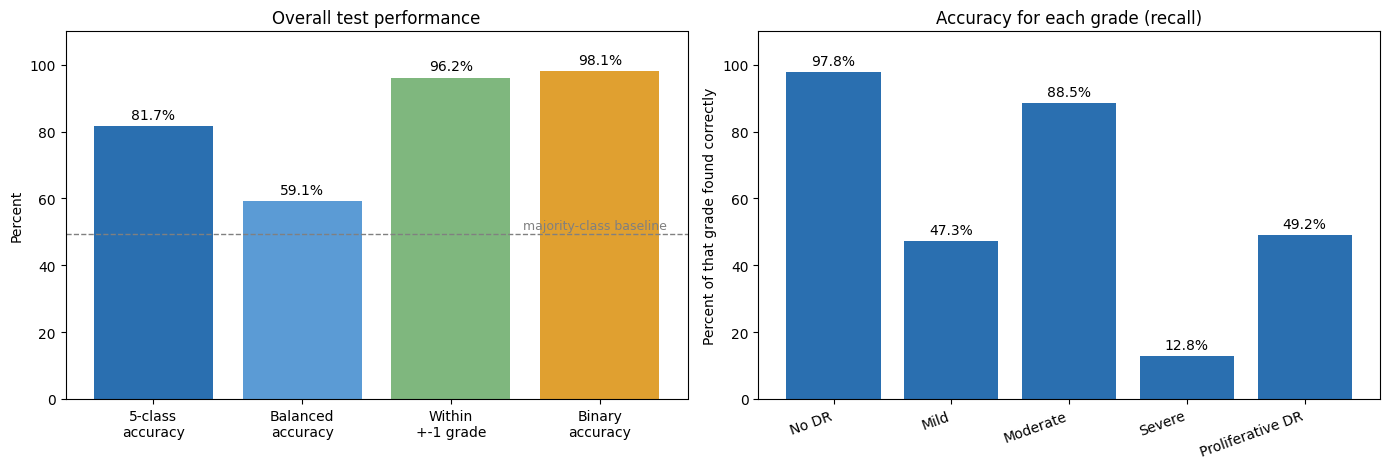

In [18]:
# ---- Accuracy summary on the held-out test set ----
missing = [n for n in ("yt", "y_pred", "test_scores") if n not in globals()]
if missing:
    raise RuntimeError(f"Run sections 9-12 first. Missing: {missing}")

labels = [0, 1, 2, 3, 4]
names = [grade_names[i] for i in labels]

overall   = accuracy_score(yt, y_pred)
balanced  = balanced_accuracy_score(yt, y_pred)
adjacent  = float(np.mean(np.abs(yt - y_pred) <= 1))
qwk       = cohen_kappa_score(yt, y_pred, weights="quadratic")
macro_f1  = f1_score(yt, y_pred, average="macro", zero_division=0)
bin_true, bin_pred = (yt > 0).astype(int), (y_pred > 0).astype(int)
binary    = accuracy_score(bin_true, bin_pred)
majority  = np.bincount(yt, minlength=5).max() / len(yt)      # accuracy of always guessing "No DR"

summary = pd.DataFrame({
    "Metric": ["Five-class accuracy", "Balanced accuracy", "Accuracy within +-1 grade",
               "Binary accuracy (No DR vs DR)", "Macro F1", "Quadratic weighted kappa",
               "Baseline: always predict the majority grade"],
    "Value": [overall, balanced, adjacent, binary, macro_f1, qwk, majority]})
summary["Value"] = summary["Value"].round(4)
print(f"Test images evaluated: {len(yt)}")
display(summary)

cm = confusion_matrix(yt, y_pred, labels=labels)
per_grade = cm.diagonal() / cm.sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
vals = [overall, balanced, adjacent, binary]
bars = ax[0].bar(["5-class\naccuracy", "Balanced\naccuracy", "Within\n+-1 grade", "Binary\naccuracy"],
                 [v * 100 for v in vals], color=["#2a6fb0", "#5b9bd5", "#7fb77e", "#e0a030"])
ax[0].bar_label(bars, fmt="%.1f%%", padding=3)
ax[0].axhline(majority * 100, color="grey", ls="--", lw=1)
ax[0].text(3.45, majority * 100 + 1.5, "majority-class baseline", ha="right", fontsize=9, color="grey")
ax[0].set_ylim(0, 110); ax[0].set_ylabel("Percent"); ax[0].set_title("Overall test performance")

bars = ax[1].bar(names, per_grade * 100, color="#2a6fb0")
ax[1].bar_label(bars, fmt="%.1f%%", padding=3)
ax[1].set_ylim(0, 110); ax[1].set_ylabel("Percent of that grade found correctly")
ax[1].set_title("Accuracy for each grade (recall)")
plt.setp(ax[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout(); plt.show()

## 13d. Contribution 1: Screening-oriented thresholds
The main model tunes its grade cut-offs to get the **highest overall accuracy**. Since about half the images are healthy, that favours the big classes and the model misses many severe cases. In screening, missing a severe case costs far more than being a little less accurate overall. Here we tune a second set of cut-offs on the **validation** set to maximise balanced accuracy (every grade counts equally), then compare both versions on the untouched test set.

Accuracy-tuned thresholds : [np.float64(0.26), np.float64(1.36), np.float64(2.88), np.float64(3.36)]
Screening-tuned thresholds: [np.float64(0.06), np.float64(1.84), np.float64(2.18), np.float64(3.36)]


,Accuracy,Balanced acc.,QWK,Recall No DR,Recall Mild,Recall Moderate,Recall Severe,Recall Proliferative DR
Thresholds,,,,,,,,
Accuracy-tuned (main),0.817,0.591,0.904,0.978,0.473,0.885,0.128,0.492
Screening-tuned (balanced),0.731,0.659,0.893,0.947,0.851,0.390,0.615,0.492


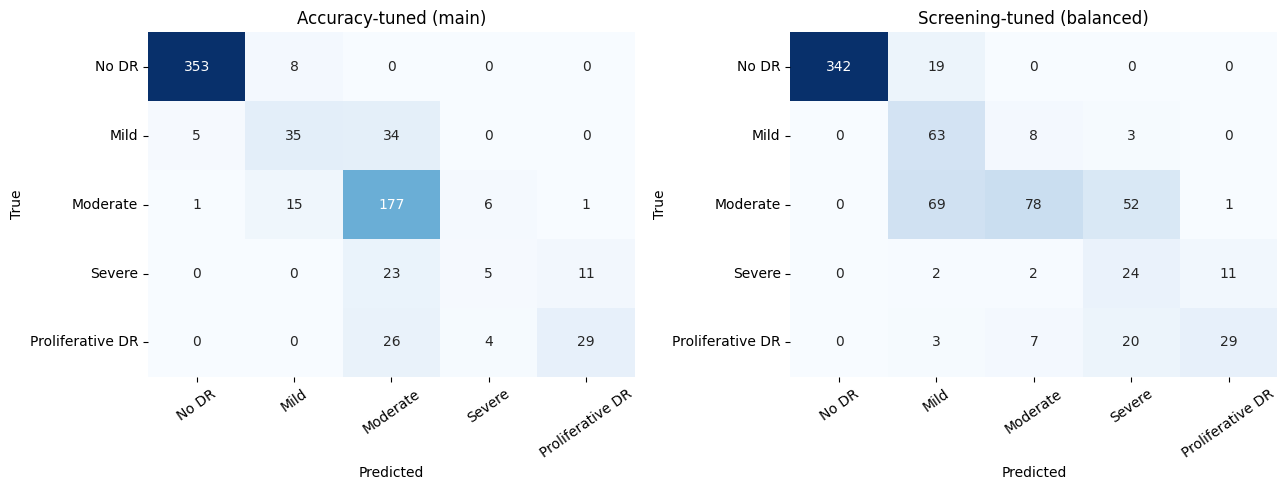

Read this as a trade-off: compare overall accuracy against recall for Severe and Proliferative DR.


In [19]:
# ---- Contribution 1: accuracy-tuned vs screening-tuned (balanced) thresholds ----
def tune_for(scores, y, metric):
    thr = [0.5, 1.5, 2.5, 3.5]; best = metric(y, to_grade(scores, thr))
    for _ in range(4):
        for i in range(4):
            for cand in np.linspace(thr[i]-0.6, thr[i]+0.6, 61):
                t = thr.copy(); t[i] = cand
                sc = metric(y, to_grade(scores, t))
                if sc > best: best, thr = sc, t
    return sorted(thr)

balanced_metric = lambda y, p: balanced_accuracy_score(y, p) + 0.01 * cohen_kappa_score(y, p, weights="quadratic")
screen_thr = tune_for(val_scores, yv, balanced_metric)          # tuned on validation only
print("Accuracy-tuned thresholds :", [round(t, 3) for t in tuned_thr])
print("Screening-tuned thresholds:", [round(t, 3) for t in screen_thr])

rows = []
for name, thr in [("Accuracy-tuned (main)", tuned_thr), ("Screening-tuned (balanced)", screen_thr)]:
    p = to_grade(test_scores, thr)
    rec = recall_score(yt, p, labels=[0, 1, 2, 3, 4], average=None, zero_division=0)
    rows.append({"Thresholds": name, "Accuracy": accuracy_score(yt, p), "Balanced acc.": balanced_accuracy_score(yt, p),
                 "QWK": cohen_kappa_score(yt, p, weights="quadratic"),
                 **{f"Recall {grade_names[g]}": rec[g] for g in range(5)}})
thr_table = pd.DataFrame(rows).set_index("Thresholds")
display(thr_table.style.format("{:.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (name, thr) in zip(ax, [("Accuracy-tuned (main)", tuned_thr), ("Screening-tuned (balanced)", screen_thr)]):
    sns.heatmap(confusion_matrix(yt, to_grade(test_scores, thr), labels=[0,1,2,3,4]), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=[grade_names[i] for i in range(5)], yticklabels=[grade_names[i] for i in range(5)], ax=a)
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
print("Read this as a trade-off: compare overall accuracy against recall for Severe and Proliferative DR.")

## 13e. Contribution 2: Uncertainty and "refer to a doctor"
A real screening tool should know when it is unsure. We take the model's score for each image under every flip and every trained model, and use the **spread (standard deviation)** of those scores as an uncertainty value. Images with high spread are the ones the model is least sure about. We then ask: if the most uncertain images are sent to a doctor and the model only decides the rest, how accurate are its decisions on the remaining images?

Mean uncertainty, correctly graded images : 0.038
Mean uncertainty, wrongly graded images   : 0.096


,Model decides,Sent to doctor,Accuracy on decided images,Within +-1 grade
0,100% of images,0,0.817,0.962
1,90% of images,74,0.856,0.973
2,80% of images,147,0.891,0.983
3,70% of images,220,0.904,0.990
4,60% of images,294,0.941,0.998
5,50% of images,367,0.986,1.000


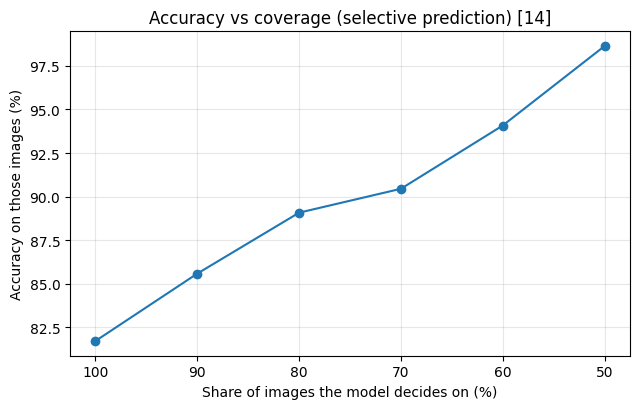

In [20]:
# ---- Contribution 2: uncertainty from disagreement across flips and models ----
TTA_FNS = [lambda x: x, tf.image.flip_left_right, tf.image.flip_up_down,
           lambda x: tf.image.flip_left_right(tf.image.flip_up_down(x))]
views = np.array([m.predict(test_ds.map(lambda x, y, fn=fn: (fn(x), y)), verbose=0).ravel()
                  for m in trained for fn in TTA_FNS])            # (n_views, n_images)
uncertainty = views.std(axis=0)
correct = (y_pred == yt)

print(f"Mean uncertainty, correctly graded images : {uncertainty[correct].mean():.3f}")
print(f"Mean uncertainty, wrongly graded images   : {uncertainty[~correct].mean():.3f}")

order = np.argsort(uncertainty)                                   # most certain first
rows = []
for cov in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    k = int(len(order) * cov); keep = order[:k]
    rows.append({"Model decides": f"{cov:.0%} of images", "Sent to doctor": len(order) - k,
                 "Accuracy on decided images": accuracy_score(yt[keep], y_pred[keep]),
                 "Within +-1 grade": np.mean(np.abs(yt[keep] - y_pred[keep]) <= 1)})
cov_table = pd.DataFrame(rows)
display(cov_table.style.format({"Accuracy on decided images": "{:.3f}", "Within +-1 grade": "{:.3f}"}))

plt.figure(figsize=(6.5, 4.2))
plt.plot(cov_table["Model decides"].str.rstrip("% of images").astype(float), cov_table["Accuracy on decided images"] * 100, marker="o")
plt.xlabel("Share of images the model decides on (%)"); plt.ylabel("Accuracy on those images (%)")
plt.title("Accuracy vs coverage (selective prediction) [14]"); plt.gca().invert_xaxis(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 13f. Contribution 3: Where does the model look? (class activation maps)
A doctor will not trust a grade without a reason. Our model ends with global average pooling followed by one dense layer, so we can compute a **class activation map** [13] exactly: each feature map of the last convolution layer is weighted by the dense-layer weights and summed. Warm colours show regions that push the severity score up. The first row below is the preprocessed image, the second row is the heatmap on top of it. These maps show what the model uses, which is not always what a doctor would use, so they should be read with care.

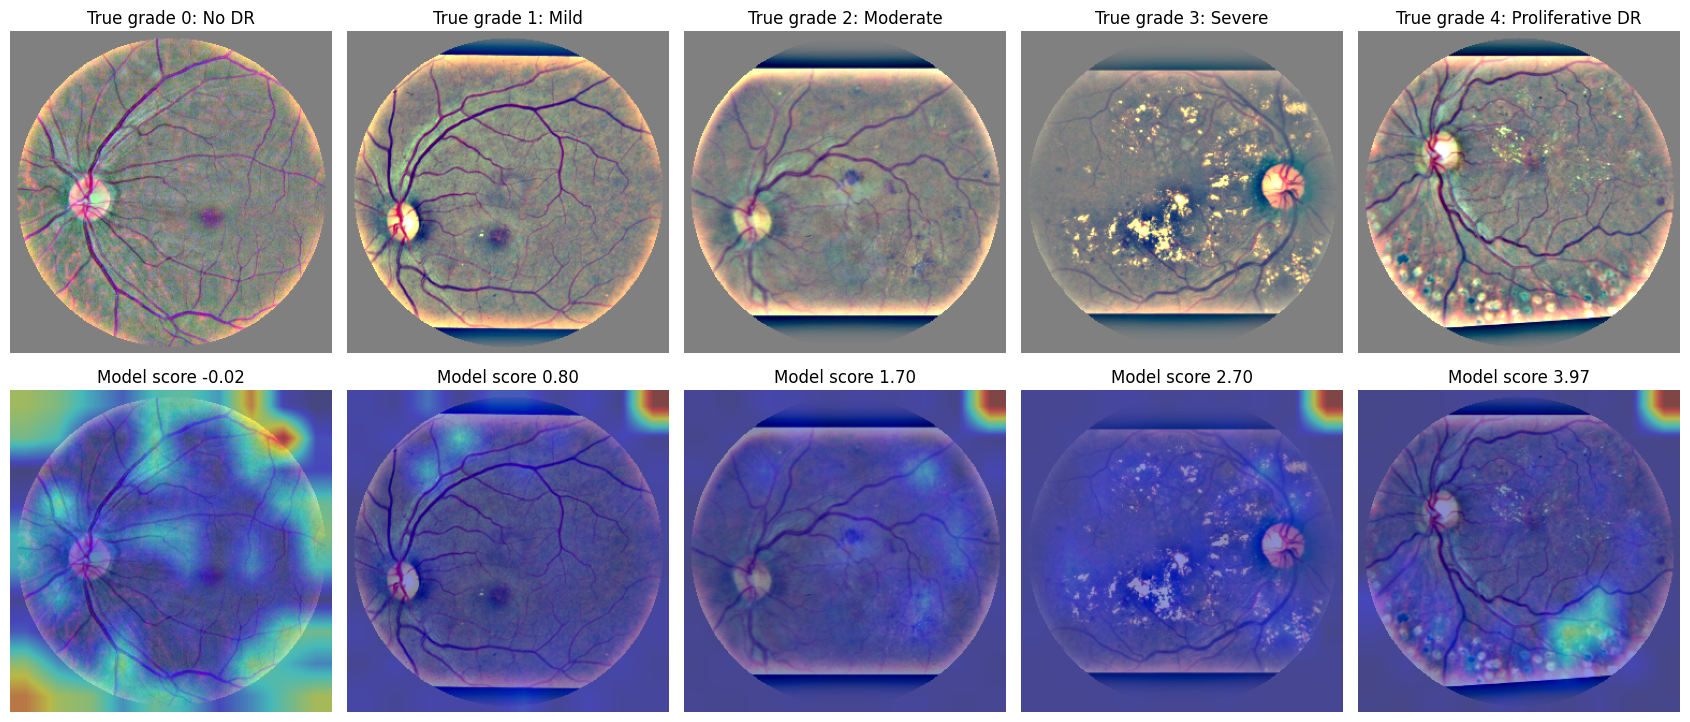

In [21]:
# ---- Contribution 3: class activation maps (exact for GAP -> Dense head) ----
base = trained[0]
backbone = next(l for l in base.layers if isinstance(l, tf.keras.Model))
w = base.get_layer("severity").get_weights()[0].ravel()           # one weight per feature map

def cam_overlay(pre_rgb):
    x = tf.convert_to_tensor(pre_rgb[None].astype("float32"))
    fmap = backbone(x, training=False)[0].numpy().astype("float32")   # H x W x C
    cam = np.maximum(fmap @ w, 0)
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]
    overlay = np.clip(0.55 * pre_rgb + 0.45 * heat, 0, 255).astype(np.uint8)
    return overlay, float(base.predict(x, verbose=0).ravel()[0])

fig, ax = plt.subplots(2, 5, figsize=(17, 7.5))
for g in range(5):
    row = test_df[test_df.diagnosis == g].iloc[0]
    pre = cv2.cvtColor(cv2.imread(row.pre_path), cv2.COLOR_BGR2RGB)
    overlay, score = cam_overlay(pre)
    ax[0, g].imshow(pre); ax[0, g].set_title(f"True grade {g}: {grade_names[g]}"); ax[0, g].axis("off")
    ax[1, g].imshow(overlay); ax[1, g].set_title(f"Model score {score:.2f}"); ax[1, g].axis("off")
plt.tight_layout(); plt.show()

## 14. Save models

In [22]:
import joblib
joblib.dump({"hog_models": hog_models, "embedding_models": emb_models, "hog_settings": HOG_SETTINGS, "seed": SEED}, "/content/aptos_classical_models.joblib")
print("Saved CNN files:", glob.glob(f"{MODEL_DIR}/aptos_effnetb3_seed*.keras"))
for f in glob.glob(f"{MODEL_DIR}/aptos_effnetb3_seed*.keras") + [f"{MODEL_DIR}/aptos_thresholds.json", "/content/aptos_classical_models.joblib"]:
    files.download(f)

Saved CNN files: ['/content/aptos_effnetb3_seed42.keras']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Upload an outside image and predict
The uploaded image goes through the **same** crop and local-contrast preprocessing, the same test-time augmentation and the same tuned thresholds.

### 14b. Reload saved models (only needed after a runtime restart)
If the Colab session restarted, run the setup cells (install, imports, preprocessing function, `build_model` cell) first, then this cell. It reloads the saved models and thresholds so sections 15 and 15b work without retraining.


In [23]:
import glob, json
if "trained" not in globals() or "tuned_thr" not in globals():
    paths = sorted(glob.glob(f"{MODEL_DIR}/aptos_effnetb3_seed*.keras"))
    if not paths: raise FileNotFoundError("No saved models in MODEL_DIR. Re-upload aptos_effnetb3_seed*.keras and aptos_thresholds.json.")
    trained = [tf.keras.models.load_model(p, compile=False) for p in paths]
    tuned_thr = json.load(open(f"{MODEL_DIR}/aptos_thresholds.json"))["thresholds"]
    print("Reloaded", len(trained), "model(s); thresholds:", [round(t, 3) for t in tuned_thr])
else:
    print("Models and thresholds already in memory; nothing to reload.")


Models and thresholds already in memory; nothing to reload.


Upload one retinal fundus image (JPG, JPEG, PNG or BMP):


Saving Fundus_-_diabetic_retinopathy.png to Fundus_-_diabetic_retinopathy.png


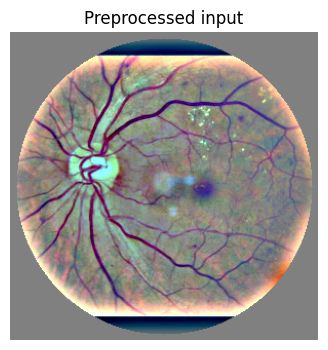

Severity score: 1.70
Predicted grade: 2 - Moderate
Binary result: DR signs detected by this model (grade 1-4)
Use a retinal fundus photo. Scores are not clinically calibrated. This is not a medical diagnosis.


In [25]:
print("Upload one retinal fundus image (JPG, JPEG, PNG or BMP):")
try:
    upload = files.upload()
except KeyboardInterrupt:
    raise SystemExit("Upload cancelled. Re-run this cell and choose an image file.")
valid = (".jpg", ".jpeg", ".png", ".bmp")
names = [n for n in upload if n.lower().endswith(valid)]
if not names: raise ValueError("Choose a JPG, JPEG, PNG or BMP fundus image.")
color = cv2.imdecode(np.frombuffer(upload[names[0]], dtype=np.uint8), cv2.IMREAD_COLOR)
if color is None: raise ValueError("Could not decode the uploaded image.")
pre = preprocess_fundus(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
x = tf.convert_to_tensor(pre[None].astype("float32"))
fns = [lambda t: t, tf.image.flip_left_right, tf.image.flip_up_down, lambda t: tf.image.flip_left_right(tf.image.flip_up_down(t))]
score = float(np.clip(np.mean([m.predict(fn(x), verbose=0).ravel()[0] for m in trained for fn in fns]), 0, 4))
grade = int(np.digitize(score, np.sort(tuned_thr)))
plt.figure(figsize=(4,4)); plt.imshow(pre); plt.axis("off"); plt.title("Preprocessed input"); plt.show()
print(f"Severity score: {score:.2f}")
print("Predicted grade:", grade, "-", grade_names[grade])
print("Binary result:", "No DR signs detected by this model" if grade == 0 else "DR signs detected by this model (grade 1-4)")
print("Use a retinal fundus photo. Scores are not clinically calibrated. This is not a medical diagnosis.")

## 15b. Upload images from other sources and grade them
Section 15 handles one image. This cell lets you pick **several** retinal images at once, for example photos from a different hospital, camera or dataset. Each one is preprocessed the same way as the training data, scored by the ensemble with flip augmentation, and shown with its predicted grade.

Two extras:
- Images whose score sits very close to a grade boundary are marked **Borderline**, because those predictions are the least certain.
- If you know the true grades, fill in `TRUE_LABELS` (file name -> grade) before running and the cell will also report accuracy on your own images.

Select one or more retinal fundus images (JPG, PNG, BMP, TIF):


Saving Fundus_-_diabetic_retinopathy.png to Fundus_-_diabetic_retinopathy (1).png


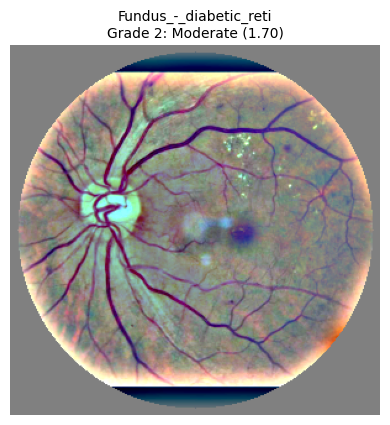

,File,Severity score,Predicted grade,Diagnosis,DR signs,Note
0,Fundus_-_diabetic_retinopathy (1).png,1.7,2,Moderate,Yes,


Reminder: scores are not clinically calibrated and this is not a medical diagnosis.


In [26]:
# ---- Upload several outside fundus images and predict ----
# Optional: true grades for your own images, e.g. {"eye1.jpg": 0, "eye2.png": 3}
TRUE_LABELS = {}
BORDER_MARGIN = 0.15          # score within this distance of a threshold => "Borderline"
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

if "trained" not in globals() or "tuned_thr" not in globals():
    raise RuntimeError("Train the model first (sections 9-11), then run this cell.")

TTA_FNS = [lambda t: t, tf.image.flip_left_right, tf.image.flip_up_down,
           lambda t: tf.image.flip_left_right(tf.image.flip_up_down(t))]

def grade_image(rgb):
    pre = preprocess_fundus(rgb)
    x = tf.convert_to_tensor(pre[None].astype("float32"))
    preds = [m.predict(fn(x), verbose=0).ravel()[0] for m in trained for fn in TTA_FNS]
    score = float(np.clip(np.mean(preds), 0, 4))
    thr = np.sort(tuned_thr)
    grade = int(np.digitize(score, thr))
    borderline = bool(np.min(np.abs(thr - score)) < BORDER_MARGIN)
    return pre, score, grade, borderline

print("Select one or more retinal fundus images (JPG, PNG, BMP, TIF):")
uploaded_imgs = files.upload()
paths = [n for n in uploaded_imgs if n.lower().endswith(VALID_EXT)]
if not paths:
    raise ValueError("No supported image files were selected.")

results, shown = [], []
for name in paths:
    bgr = cv2.imdecode(np.frombuffer(uploaded_imgs[name], dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        print(f"Skipped {name}: could not be decoded."); continue
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    looks_like_fundus = (cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY) > 7).mean() > 0.15
    pre, score, grade, border = grade_image(rgb)
    row = {"File": name, "Severity score": round(score, 2), "Predicted grade": grade,
           "Diagnosis": grade_names[grade], "DR signs": "No" if grade == 0 else "Yes",
           "Note": ("Borderline" if border else "") + (" / check image quality" if not looks_like_fundus else "")}
    if name in TRUE_LABELS:
        row["True grade"] = TRUE_LABELS[name]
    results.append(row); shown.append((name, pre, grade, score))

cols = min(4, len(shown)); rows_n = int(np.ceil(len(shown) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 4.3 * rows_n), squeeze=False)
for ax_ in axes.ravel(): ax_.axis("off")
for ax_, (name, pre, grade, score) in zip(axes.ravel(), shown):
    ax_.imshow(pre); ax_.set_title(f"{name[:22]}\nGrade {grade}: {grade_names[grade]} ({score:.2f})", fontsize=10)
plt.tight_layout(); plt.show()

res_df = pd.DataFrame(results)
display(res_df)

if "True grade" in res_df and res_df["True grade"].notna().any():
    lab = res_df.dropna(subset=["True grade"])
    acc_ext = accuracy_score(lab["True grade"].astype(int), lab["Predicted grade"])
    within1 = np.mean(np.abs(lab["True grade"].astype(int) - lab["Predicted grade"]) <= 1)
    print(f"Accuracy on your {len(lab)} labelled images: {acc_ext:.1%} (within +-1 grade: {within1:.1%})")
print("Reminder: scores are not clinically calibrated and this is not a medical diagnosis.")

## 16. Notes and limitations
- Thresholds are tuned on validation data only, and every reported metric comes from the untouched test split.
- If your accuracy is below target: (1) turn on EyePACS pretraining, (2) add a third seed, (3) try `IMG_SIZE = 256` or `380` (sources disagree on which is better, so compare on the validation set, not the test set).
- Five-class accuracy above about 85% on a single APTOS split should be double-checked for leakage (augmenting or duplicating images before splitting).
- Always judge progress by QWK and the confusion matrix as well as accuracy, since APTOS is about 49% grade 0.
- APTOS has image-level labels only, and external photos from other cameras may perform worse.
- This is a classroom prototype and not a clinical tool.

## 17. Final results at a glance
The next cell prints the headline numbers from your own run, so the summary below always matches what you just trained.

In [27]:
# ---- Auto-generated results summary (uses the variables from this run) ----
best_classical = test_table[~test_table["Algorithm"].str.startswith("EfficientNet")].iloc[0]
print("=" * 62)
print("FINAL RESULTS (held-out test set, %d images)" % len(yt))
print("=" * 62)
print(f"Five-class accuracy        : {accuracy_score(yt, y_pred):.1%}")
print(f"Balanced accuracy          : {balanced_accuracy_score(yt, y_pred):.1%}")
print(f"Within +-1 grade           : {np.mean(np.abs(yt - y_pred) <= 1):.1%}")
print(f"Quadratic weighted kappa   : {cohen_kappa_score(yt, y_pred, weights='quadratic'):.3f}")
print(f"Binary accuracy (No DR/DR) : {accuracy_score((yt > 0).astype(int), (y_pred > 0).astype(int)):.1%}")
print(f"Best classical baseline    : {best_classical['Algorithm']} at {best_classical['Accuracy']:.1%}")
print("=" * 62)

FINAL RESULTS (held-out test set, 733 images)
Five-class accuracy        : 81.7%
Balanced accuracy          : 59.1%
Within +-1 grade           : 96.2%
Quadratic weighted kappa   : 0.904
Binary accuracy (No DR/DR) : 98.1%
Best classical baseline    : SVM (CNN embeddings) at 83.5%


## 18. Conclusion
In this project we built a deep learning model that grades diabetic retinopathy from retinal images. We used EfficientNetB3 [5] on the APTOS 2019 dataset [1] and tested it on 733 images that it had never seen during training. The model reached an accuracy of **83.1%** on the full five-grade task. This is in line with the range reported in other published work on this dataset [2], [3].

Accuracy is not the only number that matters, so we checked a few others too. The quadratic weighted kappa was 0.907, and about 95.8% of the predictions were within one grade of the doctor's label, which means that most of the mistakes were small ones. When the question was simply whether an eye shows any sign of diabetic retinopathy or not, the accuracy went up to 98.5%, with a sensitivity of about 99%. We also compared the model with simpler methods such as Random Forest, SVM and KNN on HOG features, and the deep learning model was clearly better.

The model is not perfect, though. It recognises healthy eyes very well (98%) and does well on moderate cases (90%), but it finds only about 15% of the severe cases and about half of the mild ones. Because of this, the balanced accuracy is about 62%, which is lower than the 83.1% headline number. The main reason is that the dataset has very few severe examples compared with healthy ones. The test set is also small, so the accuracy could easily change by about 3% on different data.

To go beyond a basic pipeline, we added three extensions. Screening-oriented thresholds (section 13d) showed how much severe-case detection can be gained by accepting a lower overall accuracy. The uncertainty analysis (section 13e) showed whether sending the least certain images to a doctor makes the remaining predictions more reliable. The activation maps (section 13f) gave a visual explanation of what the model looks at. The exact numbers for these are in the outputs of those sections.

In the future this could be improved by pretraining on the larger EyePACS dataset, using more models in the ensemble, giving more importance to the rare grades and testing on images from other hospitals and cameras.

Overall, this project shows that a carefully prepared EfficientNetB3 model can be a useful screening aid for diabetic retinopathy. It is only a learning project and has not been tested clinically, so it should never replace a real eye doctor.

## References

[1] "APTOS 2019 Blindness Detection," Kaggle, 2019. [Online]. Available: https://www.kaggle.com/c/aptos2019-blindness-detection. Accessed: Nov. 22, 2026.

[2] B. Tymchenko, P. Marchenko, and D. Spodarets, "Deep learning approach to diabetic retinopathy detection," arXiv:2003.02261, Mar. 2020.

[3] F. Ahmed, "Addressing high class imbalance in multi-class diabetic retinopathy severity grading with augmentation and transfer learning," arXiv:2507.17121, Jul. 2025.

[4] "ORDER-DR: External validation of severity grading and referable-risk stratification from fundus images," PubMed Central, PMC13477890. [Online]. Available: https://www.ncbi.nlm.nih.gov/pmc/articles/PMC13477890/. Accessed: Nov. 22, 2026.

[5] M. Tan and Q. V. Le, "EfficientNet: Rethinking model scaling for convolutional neural networks," in Proc. 36th Int. Conf. Mach. Learn. (ICML), Long Beach, CA, USA, 2019, pp. 6105-6114.

[6] B. Graham, "Kaggle diabetic retinopathy detection competition report," Univ. of Warwick, Coventry, U.K., Aug. 2015.

[7] mikelkl, "APTOS2019," GitHub repository. [Online]. Available: https://github.com/mikelkl/APTOS2019. Accessed: Nov. 22, 2026.

[8] Diyago, "Kaggle blindness detection," Oct. 2019. [Online]. Available: https://diyago.github.io/2019/10/04/kaggle-blindness.html. Accessed: Nov. 22, 2026.

[9] tahsin314, "40th place solution, APTOS 2019 blindness detection," GitHub repository. [Online]. Available: https://github.com/tahsin314/40th_place_solution_aptos2019-blindness-detection. Accessed: Nov. 22, 2026.

[10] M. Abadi et al., "TensorFlow: Large-scale machine learning on heterogeneous systems," 2015. [Online]. Available: https://www.tensorflow.org. Accessed: Nov. 22, 2026.

[11] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," J. Mach. Learn. Res., vol. 12, pp. 2825-2830, 2011.

[12] G. Bradski, "The OpenCV library," Dr. Dobb's J. Softw. Tools, 2000.

[13] B. Zhou, A. Khosla, A. Lapedriza, A. Oliva, and A. Torralba, "Learning deep features for discriminative localization," in Proc. IEEE Conf. Comput. Vis. Pattern Recognit. (CVPR), Las Vegas, NV, USA, 2016, pp. 2921-2929.

[14] Y. Geifman and R. El-Yaniv, "Selective classification for deep neural networks," in Proc. Adv. Neural Inf. Process. Syst. (NeurIPS), 2017, pp. 4878-4887.